# Pipeline-based processing in pypillometry

In [1]:
import pypillometry as pp
from pypillometry import u

`pypillometry` implements a pipeline-like approach where each operation executed on a `PupilData`, `GazeData` or `EyeData` object returns the (modified) object. This enables the "chaining" of commands as follows:

In [2]:
# load a small example dataset
d = pp.get_example_data("rlmw_002_short")
d = d.pupil_blinks_detect(apply_mask=True)\
     .blinks_merge_close(distance=100 * u.ms, apply_mask=True)\
     .pupil_lowpass_filter(3)\
     .downsample(50)

This command loads a data file (here we use an example dataset included with `pypillometry`), detects blinks in the signal and masks them, merges short, successive blinks, applies a 3 Hz low-pass filter, and downsamples the signal to 50 Hz. The final result of this processing pipeline is stored in object `d`.

Here, for better visibility, we put each operation on a separate line. For that to work, we need to tell Python that the statement has not yet ended, which we achieve by putting a backslash `\` at the end of each (non-final) line.

We can get a useful summary of the dataset and the operations applied to it by simply printing it:

Eye,Count,Mean ± SD (ms),Range (ms)
left,14,395.7 ± 580.8,"[60.0, 2280.0]"
right,13,153.8 ± 84.6,"[60.0, 420.0]"

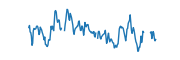
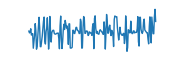
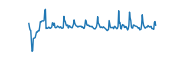
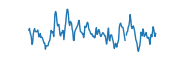
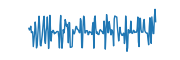
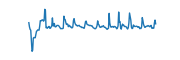

In [3]:
d

We see that sampling rate, number of datapoints and more is printed along with the history of all operations applied to the dataset. The same information can be retrieved in a form useful for further processing with the function `summary()`, which returns a `dict`:

In [4]:
d.summary()

{'name': 'test short',
 'n': 2047,
 'sampling_rate': 50,
 'eyes': ['left', 'right'],
 'data': ['left_x',
  'left_y',
  'left_pupil',
  'right_x',
  'right_y',
  'right_pupil'],
 'nevents': 40,
 'experimental_setup': {'screen_resolution': (1280, 1024),
  'physical_screen_size_mm': (300.0, 200.0),
  'eye_to_screen_distance_mm': np.float64(600.0),
  'camera_position': 'not set'},
 'calibration': 'not available',
 'duration_minutes': 0.6823333333333333,
 'start_min': np.float64(0.00015),
 'end_min': np.float64(0.6820666666666667),
 'parameters': '{}',
 'glimpse': 'EyeDataDict(vars=6,n=2047,shape=(2047,)): \n  left_x (float64): 656.5500000000001, 656.14, 654.0400000000001, 652.0199999999999, 650.4...\n  left_y (float64): 597.54, 591.5, 588.3899999999999, 593.7800000000001, 598.3199999999999...\n  left_pupil (float64): 1128.8869458721679, 1133.805818276232, 1139.706928916786, 1146.4462392731277, 1153.8027812522494...\n  right_x (float64): 775.56, 777.14, 777.08, 776.99, 778.72...\n  right_y 

The history alone can be shown with `print_history()`:

In [5]:
d.print_history()

* test short
└ fill_time_discontinuities()
 └ reset_time()
  └ pupil_blinks_detect(apply_mask=True)
   └ blinks_merge_close(distance=100 ms,apply_mask=True)
    └ pupil_lowpass_filter(3)
     └ downsample(50)


## In-place vs. copying data

By default, `pypillometry` does all operations in-place. That means, after running an operation (e.g., `d.downsample()`), the dataset will have changed and the returned object is the same object as `d`.

For example, the next code downsamples the data to 50 Hz and returns dataset `d2`. However, since the operation was in-place, the original dataset `d` has also changed:

In [6]:
d = pp.get_example_data("rlmw_002_short")
d2 = d.downsample(50)
print(f"d has {len(d)} samples")
print(f"d2 has {len(d2)} samples")
print(f"d and d2 are the same: {d is d2}")

d has 2047 samples
d2 has 2047 samples
d and d2 are the same: True


This can be tricky when re-running a cell of a notebook as the operations will be applied again to the already processed data (i.e., blink detection, downsampling, smoothing etc. will be run multiple times on the same data).

This can be prevented by adding `inplace=False` to any operation or by using `d.copy()` explicitly:

In [7]:
# using inplace=False
d = pp.get_example_data("rlmw_002_short")
d2 = d.downsample(50, inplace=False)
print(f"d has {len(d)} samples")
print(f"d2 has {len(d2)} samples")
print(f"d and d2 are the same: {d is d2}")

d has 20465 samples
d2 has 2047 samples
d and d2 are the same: False


In [8]:
# using copy()
d = pp.get_example_data("rlmw_002_short")
d2 = d.copy()
d2.downsample(50)
print(f"d has {len(d)} samples")
print(f"d2 has {len(d2)} samples")
print(f"d and d2 are the same: {d is d2}")

d has 20465 samples
d2 has 2047 samples
d and d2 are the same: False


If you prefer that operations never change the object they are called on, you can change the default for a single object (`inplace=False` when creating it) or for the whole package with `pp.set_default_inplace()`:

In [9]:
pp.set_default_inplace(False)
d = pp.get_example_data("rlmw_002_short")
d2 = d.downsample(50)
print(f"d has {len(d)} samples")
print(f"d2 has {len(d2)} samples")
pp.set_default_inplace(True)  # back to the default

d has 20465 samples
d2 has 2047 samples
